# Stochastic simulation model for Recovery test
Following is the code for stochastic simulations that predicted various patterns, including the distribution pattern, accumulation per branch, somatic phylogeny, and inter-branch SNVs.

Here, we generate artificial data for the recovery test by using the simulation.

##### Packages information used in this code:  
numpy==2.0.1  
scipy==1.15.3  
seaborn==0.13.2  
pandas==2.2.3  
matplotlib==3.10.0 

In [1]:
%matplotlib inline
import math
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import random
import copy
import numpy as np

In [2]:
from scipy import stats
from scipy.stats import norm

import itertools

In [3]:
import csv
import pandas as pd

### Elongation

In [4]:
# Func in Elongation, 260612

def mutInStemCells(num_stem, t, mu_0, Genom, st_d):

    """ Func for Elongation from a seed
    
    Args:
        num_stem  (int): Num of stem cells in a meristem
        t         (int): Num of cell divisions in elongation
        mu_0    (float): Mut rate per cell per division
        Genom     (int): Genome size
        st_d      (int): Para for somatic drift (alpha - gamma)

    Return:
        t_cells   (list): History of mutation accumulation during the elongation
    """

    t_cells = [] # list for history of stem cells in a meristem
    stem_cells = [[i, []] for i in range(num_stem)] # [(ID number）,[list of mutations]]

    t_cells = copy.deepcopy(stem_cells)

    for k in range(t): # cycle of cell divisions

        # one daughter cells
        ccells = [[0, 0] for _ in range(num_stem)]
        for i in range(num_stem):

            n_mut = np.random.poisson(mu_0)
            
            if n_mut == 0: # no mut
                ccells[i] = [stem_cells[i][0], stem_cells[i][1]]
                
            else: # mut
                lst = copy.deepcopy(stem_cells[i][1])
                for _ in range(n_mut):
                    lst.append(random.randint(1, Genom)) # sampling a mutated site
                ccells[i] = [stem_cells[i][0], lst]

        # the other daughter cells
        ccells2 = [[0, 0] for _ in range(num_stem)]

        for i in range(num_stem):

            n_mut = np.random.poisson(mu_0)

            if n_mut == 0: # no mut
                ccells2[i] = [stem_cells[i][0], stem_cells[i][1]]

            else: # mut
                lst = copy.deepcopy(stem_cells[i][1])
                for _ in range(n_mut):
                    lst.append(random.randint(1, Genom)) # sampling a mutated site
                ccells2[i] = [stem_cells[i][0], lst]

        # step1 + step2: choose cells of next meristem
        stem_cells = random.sample(ccells + random.sample(ccells2, st_d), 
                                   num_stem)  # step1: random.sample(ccells2, st_d) by gammma(num_stem - st_d)

        t_cells += copy.deepcopy(stem_cells)

    return t_cells



def mutInBrStemCells(num_stem, stem_cells, t, mu_0, Genom, st_d):

    """ Func for Elongation from a meristem

    Args:
        num_stem  (int): Num of stem cells in a meristem
        stem_cells(list): Initial stem cells
        t         (int): Num of cell divisions in elongation
        mu_0    (float): Mut rate per cell per division
        Genom     (int): Genome size
        st_d      (int): Para for somatic drift (alpha - gamma)

    Return:
        t_cells   (list): History of mutation accumulation during the elongation
    """

    t_cells = copy.deepcopy(stem_cells)
    cells = copy.deepcopy(stem_cells) # to prevent reference of stem cells in for_loop

    ccells = [[0, 0] for _ in range(num_stem)]
    ccells2 = [[0, 0] for _ in range(num_stem)]

    for k in range(t): # cycle of cell divisions

        # one daughter cells
        for i in range(num_stem):

            n_mut = np.random.poisson(mu_0)

            if n_mut == 0: # no mut
                ccells[i] = [cells[i][0], cells[i][1]]

            else: # mut
                lst = copy.deepcopy(cells[i][1])
                for _ in range(n_mut):
                    lst.append(random.randint(1, Genom)) # sampling a mutated site
                ccells[i] = [cells[i][0], lst]

        # the other daughter cells
        for i in range(num_stem):

            n_mut = np.random.poisson(mu_0)

            if n_mut == 0: # no mut
                ccells2[i] = [cells[i][0], cells[i][1]]

            else: # mut
                lst = copy.deepcopy(cells[i][1])
                for _ in range(n_mut):
                    lst.append(random.randint(1, Genom)) # sampling a mutated site
                ccells2[i] = [cells[i][0], lst]

        # step1 + step2: choose cells of next meristem
        cells = random.sample(ccells + random.sample(ccells2, st_d),
                              num_stem) # step1: random.sample(ccells2, st_d) by gammma(num_stem - st_d)

        t_cells += copy.deepcopy(cells)

    return t_cells

### Branching

In [5]:
# Wrapped Normal Distribution for sampling weights in branching

# for small sigma
def WNdist_f(x_value, mu_value, sig_value, n_value): # x, mean, var, 
    
    f_func = 1/(sig_value*math.sqrt(2*math.pi))*np.sum([math.exp(-(x_value + 2*math.pi*k - mu_value)**2/(2*sig_value**2)) for k in range(-n_value,n_value+1)]) #norm.pdf(x, loc, scale)
    
    return f_func

# for large sigma
def WNdist_g(x_value, mu_value, sig_value, n_value): # x, mean, var, 
    
    g_func = 1/(2*math.pi)*(1 + 2*np.sum([math.exp(-1/2*sig_value**2)**(k**2)*math.cos(k*(x_value-mu_value)) for k in range(1,n_value+1)])) #norm.pdf(x, loc, scale)
    
    return g_func


def WNdist(x_value, mu_value, sig_value):
    
    n_value = 5

    if sig_value < 3: # for small sigma
        dist_func = WNdist_f(x_value, mu_value, sig_value, n_value)
        
    elif sig_value >= 3: # for large sigma
        dist_func = WNdist_g(x_value, mu_value, sig_value, n_value)
        
    return dist_func


def weightList(num_stem, num_div, bias_d):
    
    """　Func for weight list in Branching
    Args:
        num_stem  (int): Num of stem cells in a meristem
        num_div   (int): Num of cell divisions in branching
        bias_d  (float): Degree of bias in branching (sigma of WN distribution)
        
    Return:
        w_list/np.sum(w_list) (ndarray): Weight list for sampling in branching
    """
    
    cell_dt = 2*math.pi/(num_stem*(2**num_div)) # distance between cells
    mean_num = random.uniform(0,2*math.pi) # center of dist
    
    w_list = np.array([WNdist(i*cell_dt, mean_num, bias_d) for i in range(num_stem*(2**num_div))])
        
    return w_list/np.sum(w_list)

In [6]:
#Sampling of stem cells in Branching

def sample(stem_cells, num_stem, num_div, mu_0, Genom, bias_d):
    
    """　Func for sampling in Branching
    Args:
        stem_cells (list): List of a meristem
        num_stem    (int): Num of stem cells in a meristem
        num_div     (int): Num of cell divisions in branching
        mu_0      (float): Mut rate per cell per division
        Genom       (int): Genome size
        bias_d    (float): Degree of bias in branching (sigma of WN distribution)
        
    Return:
        sample (list): Sampled cells for axillary meristem
    """

    w_list = weightList(num_stem, num_div, bias_d)
    cells = copy.deepcopy(stem_cells[-num_stem:])

    for k in range(0,num_div):

        ccells = [[0,0] for i in range(len(cells))]
        ccells2 = [[0,0] for i in range(len(cells))]

        # one daughter cells
        for i in range(len(cells)):
            m = random.random()
            if m > mu_0: # non mutaion
                ccells[i] = [copy.deepcopy(cells[i][0]), copy.deepcopy(cells[i][1])]
            else: # mutation
                lst = ''
                lst = copy.deepcopy(cells[i][1])
                lst.append(random.randint(1,Genom)) # site of Genom in which mut occure
                ccells[i] = [copy.deepcopy(cells[i][0]), lst]

        # the other daughter cells
        for i in range(len(cells)):
            m = random.random()
            if m > mu_0: # non mutaion
                ccells2[i] = [copy.deepcopy(cells[i][0]), copy.deepcopy(cells[i][1])]
            else: # mutaion
                lst = copy.deepcopy(cells[i][1])
                lst.append(random.randint(1,Genom)) # site of Genom in which mut occure
                ccells2[i] = [copy.deepcopy(cells[i][0]), lst]

        lst2 = [] # list for daughter cells
        for p,q in zip(ccells,ccells2):
            lst2.append(p)
            lst2.append(q)

        cells = copy.deepcopy(lst2) # daughter cells arranged in genealogical order.

        #print(cells) #check

    sample_num = np.random.choice([i for i in range(len(cells))], size=num_stem, replace=False, p=w_list) # sampling of cells for axillary meristem
    sample = [cells[i] for i in sample_num]

    return sample

### Mutation matrix

In [7]:
# detection of mutated site of whole meristems of tree
def pickUpMut(allmutList):
    mutList = []
    for i in allmutList:
        for j in i[1]:
            mutList.append(j)
            
    re_allmutList = list(set(mutList)) # eliminate overlapping of mutation
    re_allmutList.sort()
    
    return re_allmutList

# making mutation matrix from history of meristems
def makeMutMatrix(stem_cells, mutList, num_stem): # List_of_meristems、list_of_all_mutated_site、Num_of_stemcells
    
    """　Func for sampling in Branching
    Args:
        stem_cells (list): List of a meristem
        mutList    (list): List of all mutated sites
        num_stem    (int): Num of stem cells in a meristem
        
    Return:
        sample (list): Sampled cells for axillary meristem
    Note:
        return is the vector of mutated states in the meristem (its length is given in mutated sites), 
        not the mutated matrix itself.
    """
    
    mutMatrix = [[] for i in range(len(stem_cells))] # Mutation matrix
    for i,j in enumerate(stem_cells):
        for k in mutList:
            if k in j[1]:
                mutMatrix[i].append(1)
            else:
                mutMatrix[i].append(0)
    # check
    for i,j in zip(stem_cells, mutMatrix):
        if len(i[1]) != sum(j):
            print("mutation occured at the same site")
            break
    
    # sum into meristems
    np_mer_mutMatrix = np.array([0 for i in range(int(len(stem_cells)/num_stem))])
    for i in range(int(len(mutMatrix)/num_stem)): # int(len(mutMatrix)/num_stem) = number of history of merstems
        
        mer_mutVector = np.zeros(len(mutList),dtype = int)
        for j in range(num_stem):
            arraylist = np.array(mutMatrix[i*num_stem +j])
            mer_mutVector = mer_mutVector + arraylist
        
        if i == 0:
            np_mer_mutMatrix = mer_mutVector
        else:
            np_mer_mutMatrix = np.vstack((np_mer_mutMatrix, mer_mutVector))
            
    return np_mer_mutMatrix

### for saving the data in .npy

In [8]:
#_for saving the data

#for saving chage the shape of list
def add_None_func(ori_List):
    max_length = max([len(i[0]) for i in ori_List]) #scaling of maximum length
    none_List = np.array([[None] for _ in range(len(ori_List[0]))]) #len(ori_List[0]): len(copy_List) due to the type of data
    
    pre_List = []
    #count = 0 #check
    for j_ in ori_List: #loop by NumTime
        #count += 1 #check
        copy_List = copy.deepcopy(j_)
        
        while len(copy_List[0]) < max_length: #len(i_[0]): number of mutations
            copy_List = np.hstack((copy_List ,none_List))
           
        pre_List.append(copy.deepcopy(copy_List))
        #print(count)#check
    
    return pre_List

#for Refrost data
def non_None(ori_List):
    non_matrix = []
    for i in ori_List:
        pre_matrix = []
        for j in i:
            pre_matrix.append([k for k in j if k is not None])
        non_matrix.append(np.array(copy.deepcopy(pre_matrix)))

    return non_matrix

In [9]:
#null regression
def reg1dim(x, y):
    a = np.dot(x, y)/ (x ** 2).sum()
    return a

### Producing parameters

In [20]:
# Parameters

ind = 'S1' # ID of individual
mut_dict_da = {'S1':7.08e-09, 'S2':4.27e-09, 'F1':1.77e-09, 'F2':1.29e-09} # S1, S2, F1, F2
mut_middle = mut_dict_da[ind]


for num_stem in [3]:
    
    # Conserved model parameters
    div_num = 10
    
    cons_para_set = []
    for mut_rate in [mut_middle/2, mut_middle, mut_middle*2]:
        for model_id in [1, 2]:
            
            para_list = [num_stem, mut_rate, 0,0,0, div_num, model_id]
            cons_para_set.append(para_list)
    # print(cons_para_set)
    
    # Replaced model parameters
    repl_para_set = []
    for mut_rate in [mut_middle/2, mut_middle, mut_middle*2]:
        for div_num in [3, 10, 30]:
            for model_id in [3, 4]:
                
                para_list = [num_stem, mut_rate, 0,0,0, div_num, model_id]
                repl_para_set.append(para_list)
    # print(repl_para_set)

    if num_stem == 3:
        para_set_NumStem3 = cons_para_set + repl_para_set

# print(para_set_NumStem3)

In [21]:
def sim_som_mut(ind, para_list):

    # Pre- parameters -------------------------------
    paraL = [None] + para_list

    NumStem = paraL[1]
    div = paraL[6]
    
    # mutation rate per cell division
    if ind == 'S1':
        µ = paraL[2]/div *388801756
    elif ind == 'S2':
        µ = paraL[3]/div *320739335
    elif ind == 'F1':
        µ = paraL[4]/div *323729573
    elif ind == 'F2':
        µ = paraL[5]/div *263488812
    
    # dynamics
    if paraL[-1] == 1: # stru-unbias
        StD = 0; biasVar = 10
    elif paraL[-1] == 2: # stru-bias
        StD = 0; biasVar = 0.5
    elif paraL[-1] == 3: # stoc-unbias
        StD = NumStem; biasVar = 10
    elif paraL[-1] == 4: # stoc-bias
        StD = NumStem; biasVar = 0.5
    
    # para only for simulation model
    GenSize = 3.4*10**8
    NumDiv = 7 # Num of div in branching
    µ_b = 0 # Mutation rate in branching, 260612
    nElim = 0 # Threshold of detection
    
    # branch length ----------------------------------
    
    br_len_S1 = [21.79, 8, 10, 11.75, 15, 14.18, 4.74, 11.3, 8.9, 8.1, 2.05, 3.2, 2.9]
    br_len_S2 = [22.2, 3.3, 3.6, 7.5, 4.1, 9.25, 9.1, 6.8, 3.6, 3.3, 5.35, 2.7, 2.4]
    br_len_F1 = [23.71, 4.4, 6.4, 13.1, 6.35, 9.65, 4.8, 5.4, 3.1, 2.75, 6.05, 1.5, 1.4]
    br_len_F2 = [25.27, 2.1, 3.8, 8.9, 1.1, 8.2, 5.8, 10.4, 2.4, 2.4, 6.45, 2.8, 3.3]
    
    if ind == 'S1':
        brlist_ = br_len_S1
    elif ind == 'S2':
        brlist_ = br_len_S2
    elif ind == 'F1':
        brlist_ = br_len_F1
    elif ind == 'F2':
        brlist_ = br_len_F2

    # given parameters ---------------------------------
    numBranch = 7
    br_ID = ['11','10','21','20','31','30','40']
    
    s0_0 = round(brlist_[0] *div)
    s0_1 = round(brlist_[1] *div)
    s0_2 = round(brlist_[2] *div)
    s0_3 = round(brlist_[3] *div)
    
    b10_0 = round(brlist_[4] *div)
    b10_1 = round(brlist_[5] *div) 
    b11   = round(brlist_[6] *div)
    
    b20_0 = round(brlist_[7] *div)
    b20_1 = round(brlist_[8] *div)
    b21   = round(brlist_[9] *div)
    
    b30_0 = round(brlist_[10] *div)
    b30_1 = round(brlist_[11] *div)
    b31   = round(brlist_[12] *div)
    
    meristemAge = [s0_0+b10_0+b11, s0_0+b10_0+b10_1, s0_0+s0_1+b20_0+b21, s0_0+s0_1+b20_0+b20_1, s0_0+s0_1+s0_2+b30_0+b31, s0_0+s0_1+s0_2+b30_0+b30_1, s0_0+s0_1+s0_2+s0_3]
    
        
    # Make mut List, 240227, 260612
    # Simulation begin -----------------------------------------------------------------------------
    List_s0_0 = mutInStemCells(NumStem, s0_0, µ, GenSize, StD)
    
    
    List_b10_0 = mutInBrStemCells(NumStem, sample(List_s0_0, NumStem, NumDiv, µ_b, GenSize, biasVar), 
                                  b10_0, µ, GenSize, StD)
    
    List_b11 = mutInBrStemCells(NumStem, sample(List_b10_0, NumStem, NumDiv, µ_b, GenSize, biasVar), 
                                b11, µ, GenSize, StD)
    
    List_b10_1 = mutInBrStemCells(NumStem, sample(List_b10_0, NumStem, NumDiv, µ_b, GenSize, biasVar), 
                                  b10_1, µ, GenSize, StD)
    
    
    List_s0_1 = mutInBrStemCells(NumStem, sample(List_s0_0, NumStem, NumDiv, µ_b, GenSize, biasVar), 
                                 s0_1, µ, GenSize, StD)
    
    
    List_b20_0 = mutInBrStemCells(NumStem, sample(List_s0_1, NumStem, NumDiv, µ_b, GenSize, biasVar),
                                  b20_0, µ, GenSize, StD)
    
    List_b21 = mutInBrStemCells(NumStem, sample(List_b20_0, NumStem, NumDiv, µ_b, GenSize, biasVar), 
                                b21, µ, GenSize, StD)
    
    List_b20_1 = mutInBrStemCells(NumStem, sample(List_b20_0, NumStem, NumDiv, µ_b, GenSize, biasVar), 
                                  b20_1, µ, GenSize, StD)
    
    
    List_s0_2 = mutInBrStemCells(NumStem, sample(List_s0_1, NumStem, NumDiv, µ_b, GenSize, biasVar),
                                 s0_2, µ, GenSize, StD)

    
    List_b30_0 = mutInBrStemCells(NumStem, sample(List_s0_2, NumStem, NumDiv, µ_b, GenSize, biasVar), 
                                  b30_0, µ, GenSize, StD)
    
    List_b31 = mutInBrStemCells(NumStem, sample(List_b30_0, NumStem, NumDiv, µ_b, GenSize, biasVar), 
                                b31, µ, GenSize, StD)
    
    List_b30_1 = mutInBrStemCells(NumStem, sample(List_b30_0, NumStem, NumDiv, µ_b, GenSize, biasVar), 
                                  b30_1, µ, GenSize, StD)
    

    List_s0_3 = mutInBrStemCells(NumStem, sample(List_s0_2, NumStem, NumDiv, µ_b, GenSize, biasVar),
                                 s0_3, µ, GenSize, StD)
    # Simulation end -----------------------------------------------------------------------------------
    
    # Pickup mutation frome whole tree
    allMutations = pickUpMut(List_s0_0+List_b10_0+List_b11+List_b10_1+List_s0_1+List_b20_0+List_b21+List_b20_1+List_s0_2+List_b30_0+List_b31+List_b30_1+List_s0_3)
    
    # Pickup mutation at the end of branches
    endallMutations = pickUpMut(List_b11+List_b10_1+List_b21+List_b20_1+List_b31+List_b30_1+List_s0_3)

    # Make mut-matrix, 260520
    ListTip_s0_3_mut_matrix  = makeMutMatrix(List_s0_3, allMutations, NumStem)
    ListTip_b10_1_mut_matrix = makeMutMatrix(List_b10_1, allMutations, NumStem)
    ListTip_b11_mut_matrix   = makeMutMatrix(List_b11, allMutations, NumStem)
    ListTip_b20_1_mut_matrix = makeMutMatrix(List_b20_1, allMutations, NumStem)
    ListTip_b21_mut_matrix   = makeMutMatrix(List_b21, allMutations, NumStem)
    ListTip_b30_1_mut_matrix = makeMutMatrix(List_b30_1, allMutations, NumStem)
    ListTip_b31_mut_matrix   = makeMutMatrix(List_b31, allMutations, NumStem)

    #at the tip of branches,260520 + 2
    pre_br_brmutMatrix = np.array([ListTip_b11_mut_matrix[-1,:], ListTip_b10_1_mut_matrix[-1,:], 
                                   ListTip_b21_mut_matrix[-1,:], ListTip_b20_1_mut_matrix[-1,:],
                                   ListTip_b31_mut_matrix[-1,:], ListTip_b30_1_mut_matrix[-1,:],
                                   ListTip_s0_3_mut_matrix[-1,:]])
    
    br_brmutMatrix = np.array([i for i in pre_br_brmutMatrix.T if sum(i)!=0]).T # mutations only in the tip of branches

    return br_brmutMatrix

In [22]:
sim_som_mut(ind, para_set_NumStem3[0])

array([[0, 0, 1, ..., 0, 0, 0],
       [0, 1, 3, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 1, 2],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 1, 0, 0],
       [1, 0, 0, ..., 0, 0, 0]])

In [28]:
# Simulating results

para_res_list = []

NumTime = 10 # Num of simulations

for para_list in para_set_NumStem3:
    results_list = []
    for _ in range(NumTime):

        # Simulation
        sim_result = sim_som_mut(ind, para_list)
        results_list.append(sim_result)

    para_res_list.append(
        (para_list, results_list)
    )

In [29]:
import os
import pickle

os.makedirs("simulation_results", exist_ok=True)

with open("simulation_results/para_recov_NumStem3.pkl", "wb") as f:
    pickle.dump(para_res_list, f)

In [33]:
para_res_list

[([10, 3.54e-09, 0, 0, 0, 10, 1],
  [array([[0, 0, 0, ..., 0, 0, 1],
          [0, 0, 0, ..., 0, 0, 1],
          [2, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 6],
          [0, 0, 0, ..., 2, 0, 1],
          [0, 0, 1, ..., 1, 1, 4]]),
   array([[1, 0, 1, ..., 2, 0, 0],
          [2, 0, 2, ..., 0, 0, 1],
          [0, 0, 2, ..., 2, 1, 0],
          ...,
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 1, 0, 0]]),
   array([[0, 0, 0, ..., 0, 0, 1],
          [1, 0, 1, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 1, 0],
          ...,
          [0, 0, 0, ..., 1, 0, 0],
          [0, 0, 0, ..., 0, 0, 0],
          [0, 0, 0, ..., 0, 0, 0]]),
   array([[1, 0, 1, ..., 1, 0, 0],
          [1, 0, 0, ..., 2, 0, 2],
          [0, 0, 0, ..., 0, 0, 0],
          ...,
          [0, 0, 0, ..., 2, 0, 0],
          [0, 0, 0, ..., 4, 0, 0],
          [0, 1, 0, ..., 3, 1, 0]]),
   array([[0, 0, 0, ..., 1, 0, 0],
          [0, 0, 0, ...

### Check by Plotting

In [34]:
# Calcualting inter-branch mutations

def ibm_dist_sampling_func(br_brmutMatrix, NumStem):
    
    n_sampling = 10
    numBranch = np.array(br_brmutMatrix).shape[0]
    
    mut_dif_M_samples = np.zeros(
        shape=(n_sampling, numBranch, numBranch)
    )
    
    for s in range(n_sampling):
    
        mut_dif_M = np.zeros(shape=(numBranch, numBranch))
    
        for l in range(numBranch):
            for k in range(numBranch):
    
                if l != k:
                    br_l = np.array(br_brmutMatrix[l])
                    br_k = np.array(br_brmutMatrix[k])
    
                    # Random sampling for each mutation
                    sample_l = np.random.binomial(1, br_l / NumStem)
                    sample_k = np.random.binomial(1, br_k / NumStem)
    
                    ib_dif = sample_l != sample_k
    
                    mut_dif_M[l][k] = np.sum(ib_dif)
    
        mut_dif_M_samples[s] = mut_dif_M

    return mut_dif_M_samples

In [41]:
# branch length

br_len_S1 = [21.79, 8, 10, 11.75, 15, 14.18, 4.74, 11.3, 8.9, 8.1, 2.05, 3.2, 2.9]
br_len_S2 = [22.2, 3.3, 3.6, 7.5, 4.1, 9.25, 9.1, 6.8, 3.6, 3.3, 5.35, 2.7, 2.4]
br_len_F1 = [23.71, 4.4, 6.4, 13.1, 6.35, 9.65, 4.8, 5.4, 3.1, 2.75, 6.05, 1.5, 1.4]
br_len_F2 = [25.27, 2.1, 3.8, 8.9, 1.1, 8.2, 5.8, 10.4, 2.4, 2.4, 6.45, 2.8, 3.3]

if ind == 'S1':
    brlist_ = br_len_S1
elif ind == 'S2':
    brlist_ = br_len_S2
elif ind == 'F1':
    brlist_ = br_len_F1
elif ind == 'F2':
    brlist_ = br_len_F2

# given parameters
numBranch = 7
br_ID = ['11','10','21','20','31','30','40']

s0_0 = brlist_[0]
s0_1 = brlist_[1]
s0_2 = brlist_[2]
s0_3 = brlist_[3]

b10_0 = brlist_[4]
b10_1 = brlist_[5]
b11   = brlist_[6]

b20_0 = brlist_[7]
b20_1 = brlist_[8]
b21   = brlist_[9]

b30_0 = brlist_[10]
b30_1 = brlist_[11]
b31   = brlist_[12]

brTimeMatrix = np.array([[0, b10_1+b11, b11+b10_0+s0_1+b20_0+b21, b11+b10_0+s0_1+b20_0+b20_1, b11+b10_0+s0_1+s0_2+b30_0+b31, b11+b10_0+s0_1+s0_2+b30_0+b30_1, s0_3+s0_2+s0_1+b10_0+b11],
                         [0,0, b10_1+b10_0+s0_1+b20_0+b21, b10_1+b10_0+s0_1+b20_0+b20_1, b10_1+b10_0+s0_1+s0_2+b30_0+b31, b10_1+b10_0+s0_1+s0_2+b30_0+b30_1, s0_3+s0_2+s0_1+b10_0+b10_1],
                         [0,0,0, b21+b20_1, b21+b20_0+s0_2+b30_0+b31, b21+b20_0+s0_2+b30_0+b30_1, s0_3+s0_2+b20_0+b21], 
                         [0,0,0,0, b20_1+b20_0+s0_2+b30_0+b31, b20_1+b20_0+s0_2+b30_0+b30_1, s0_3+s0_2+b20_0+b20_1], 
                         [0,0,0,0,0, b30_1+b31, s0_3+b30_0+b31],
                         [0,0,0,0,0,0, s0_3+b30_0+b30_1], 
                         [0,0,0,0,0,0,0]])

for kcut,k in enumerate(brTimeMatrix):
    for lcut,l in enumerate(brTimeMatrix):
        if kcut > lcut:
            brTimeMatrix[kcut][lcut]= l[kcut]

In [51]:
test = ibm_dist_sampling_func(para_res_list[0][1][0], NumStem = 3)

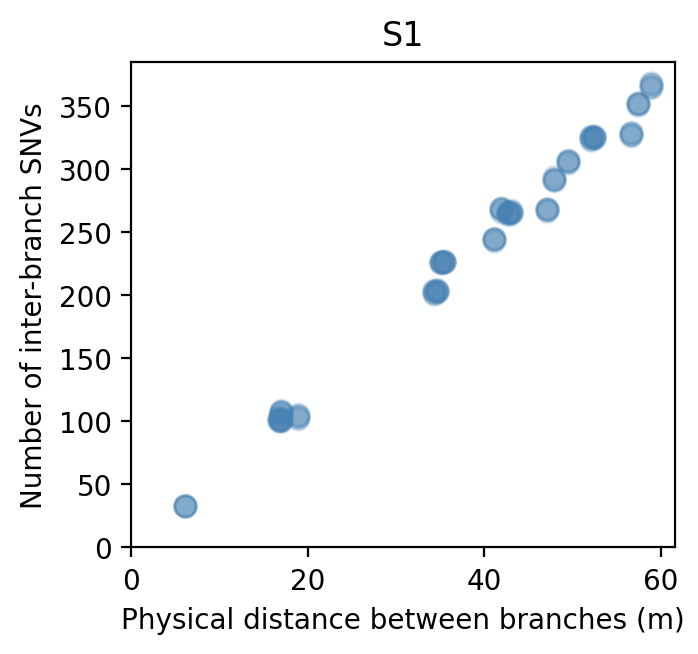

In [63]:
# Plotting --------------------------------------------------------------------------
plt.figure(figsize=(3.50394, 0.9*3.50394), dpi=200) # 3.50394 inch = 89 mm (1 column)

colordict = {'S1':'steelblue', 'S2':'skyblue', 'F1':'red', 'F2':'orange'}

# Flattening physical distance between branches
pre_mutCor_x = []
for i in range(numBranch):
    for j in range(numBranch):
        if i<j:
            pre_mutCor_x.append(brTimeMatrix[i][j]/div)

mutCor_x = np.array(pre_mutCor_x).flatten()

for ibm_m in test:
    numBranch = len(ibm_m) # number of branches
    
    # Flattening genetic distance between branches
    pre_mutCor_y = []
    for i in range(numBranch):
        for j in range(numBranch):
            if i<j:
                pre_mutCor_y.append(ibm_m[i][j]) 
                
    mutCor_y = np.array(pre_mutCor_y).flatten()
    
    plt.scatter(mutCor_x, mutCor_y, s=60, marker='o', alpha=1/10, c=colordict[ind])

plt.title(ind)
plt.xlabel('Physical distance between branches (m)')
plt.ylabel('Number of inter-branch SNVs')
plt.xlim(0,); plt.ylim(0,)
plt.show()
# ----------------------------------------------------------------------------------------

In [58]:
# openning simulated data

import pickle
with open("simulation_results/para_recov_NumStem3.pkl", "rb") as f:
    sim_data = pickle.load(f)

NumStem = 3

[3, 3.54e-09, 0, 0, 0, 10, 1]


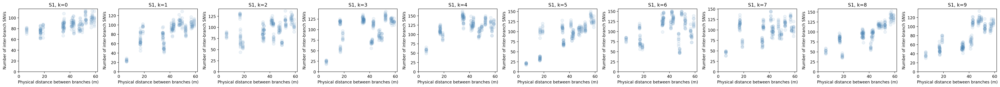

[3, 3.54e-09, 0, 0, 0, 10, 2]


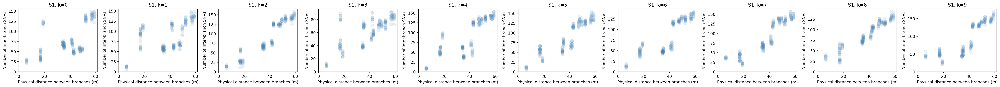

[3, 7.08e-09, 0, 0, 0, 10, 1]


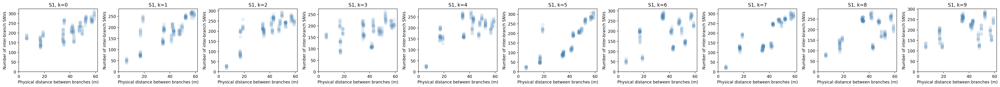

[3, 7.08e-09, 0, 0, 0, 10, 2]


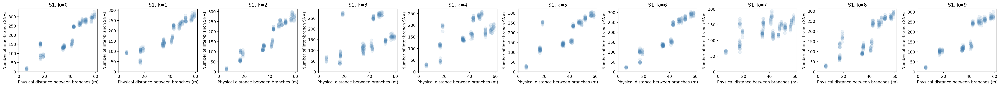

[3, 1.416e-08, 0, 0, 0, 10, 1]


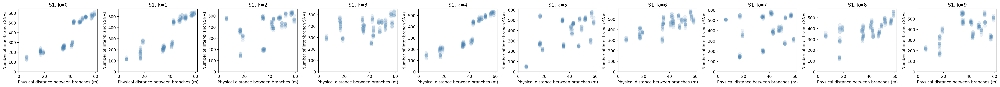

[3, 1.416e-08, 0, 0, 0, 10, 2]


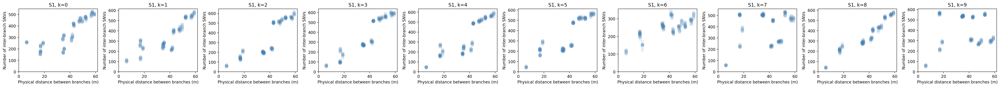

[3, 3.54e-09, 0, 0, 0, 3, 3]


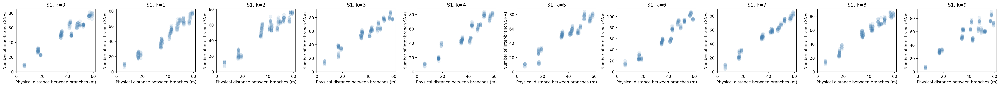

[3, 3.54e-09, 0, 0, 0, 3, 4]


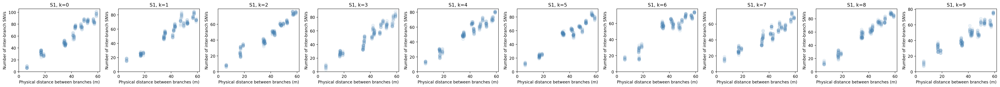

[3, 3.54e-09, 0, 0, 0, 10, 3]


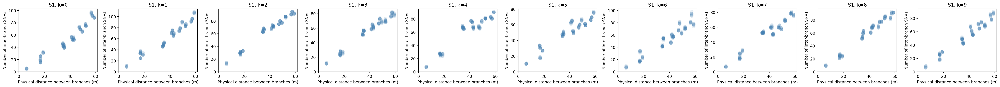

[3, 3.54e-09, 0, 0, 0, 10, 4]


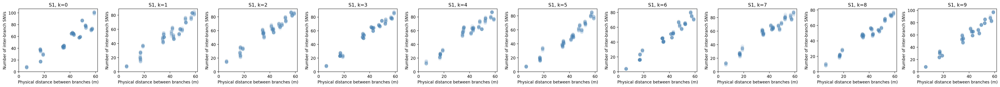

[3, 3.54e-09, 0, 0, 0, 30, 3]


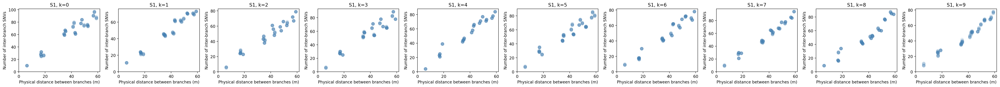

[3, 3.54e-09, 0, 0, 0, 30, 4]


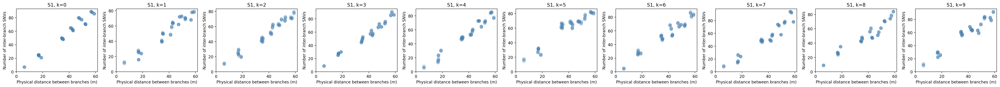

[3, 7.08e-09, 0, 0, 0, 3, 3]


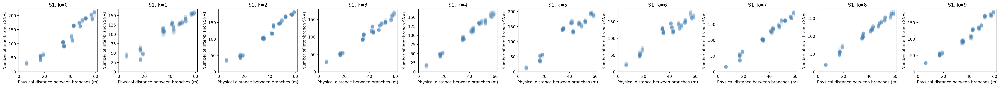

[3, 7.08e-09, 0, 0, 0, 3, 4]


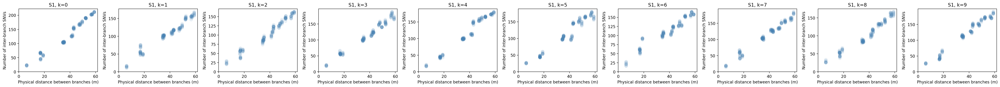

[3, 7.08e-09, 0, 0, 0, 10, 3]


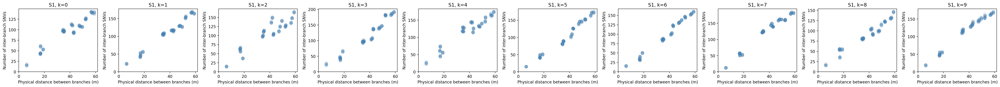

[3, 7.08e-09, 0, 0, 0, 10, 4]


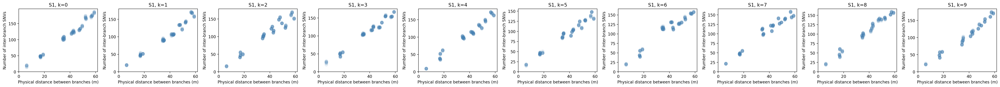

[3, 7.08e-09, 0, 0, 0, 30, 3]


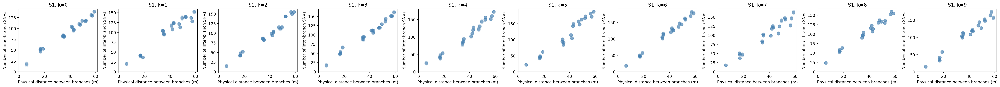

[3, 7.08e-09, 0, 0, 0, 30, 4]


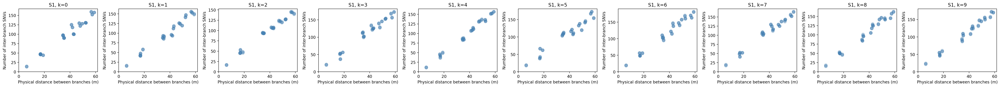

[3, 1.416e-08, 0, 0, 0, 3, 3]


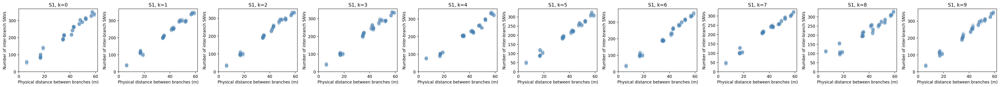

[3, 1.416e-08, 0, 0, 0, 3, 4]


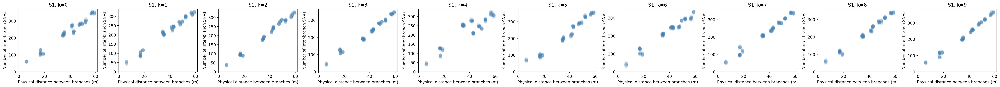

[3, 1.416e-08, 0, 0, 0, 10, 3]


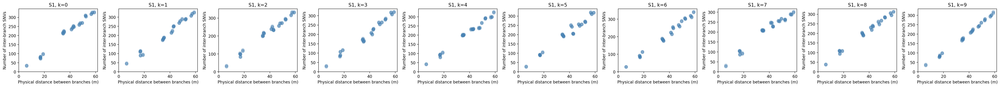

[3, 1.416e-08, 0, 0, 0, 10, 4]


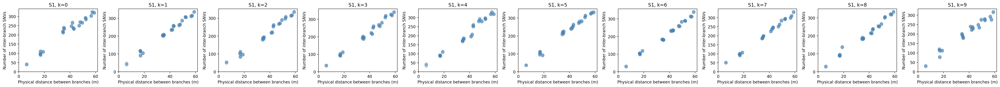

[3, 1.416e-08, 0, 0, 0, 30, 3]


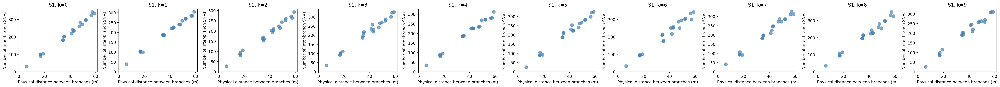

[3, 1.416e-08, 0, 0, 0, 30, 4]


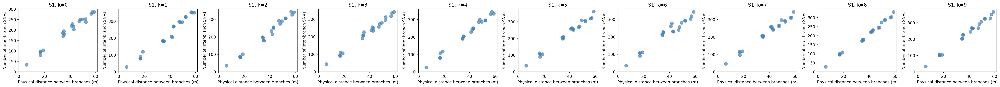

In [59]:
for para_res in sim_data:

    print(para_res[0])

    n_col = len(para_res[1])

    fig, axes = plt.subplots(
        1, n_col,
        figsize=(3.50394 * n_col, 0.9 * 3.50394),
        dpi=200,
        squeeze=False
    )
    axes = axes[0]

    colordict = {'S1':'steelblue', 'S2':'skyblue', 'F1':'red', 'F2':'orange'}

    # Flattening physical distance between branches
    pre_mutCor_x = []
    for i in range(numBranch):
        for j in range(numBranch):
            if i < j:
                pre_mutCor_x.append(brTimeMatrix[i][j] / div)

    mutCor_x = np.array(pre_mutCor_x).flatten()

    for k in range(n_col):

        test = ibm_dist_sampling_func(
            para_res[1][k],
            NumStem=NumStem
        )

        ax = axes[k]

        for ibm_m in test:
            numBranch = len(ibm_m)

            # Flattening genetic distance between branches
            pre_mutCor_y = []
            for i in range(numBranch):
                for j in range(numBranch):
                    if i < j:
                        pre_mutCor_y.append(ibm_m[i][j])

            mutCor_y = np.array(pre_mutCor_y).flatten()

            ax.scatter(
                mutCor_x,
                mutCor_y,
                s=60,
                marker='o',
                alpha=1/10,
                c=colordict[ind]
            )

        ax.set_title(f'{ind}, k={k}')
        ax.set_xlabel('Physical distance between branches (m)')
        ax.set_ylabel('Number of inter-branch SNVs')
        ax.set_xlim(0,)
        ax.set_ylim(0,)

    plt.tight_layout()
    plt.show()